# Dinâmica do mercado de itens CS:GO

Este caderno trata o mercado como uma série. A ordem vai do nível ao comportamento: o índice e a
volatilidade, a dinâmica (autocorrelação, correlação com o mercado, raiz unitária e agrupamento de
volatilidade), o ruído de preço que explica parte da autocorrelação e a estacionariedade de cada item. O
mercado é a média simples dos retornos diários dos itens.

In [1]:
from argparse import ArgumentParser
from pathlib import Path

import altair as alt
import polars as pl
from great_tables import GT
from helpers.export import inline_table_styles, write_outputs
from helpers.formatting import format_metric, metric_text_table
from helpers.market import LAGS, market_dynamics, market_series, market_with_volatility
from helpers.noise import price_noise
from helpers.params import load_params
from helpers.paths import repo
from helpers.runtime import notebook_arguments
from helpers.schemas import read_table
from helpers.stationarity import item_stationarity

In [2]:
# GitHub shows PNG output but not Vega-Lite.
alt.renderers.enable("png")

# GitHub drops style blocks, so the tables keep their styles inline.
inline_table_styles()

DYNAMICS_LABELS = {
    "market_mean_return": "Retorno diário médio do mercado",
    "market_std_return": "Desvio padrão do retorno do mercado",
    **{f"market_lag_{lag}": f"Autocorrelação do mercado (defasagem {lag})" for lag in LAGS},
    **{f"asset_lag_{lag}": f"Autocorrelação dentro dos itens (defasagem {lag})" for lag in LAGS},
    "mean_market_correlation": "Correlação média dos itens com o mercado",
    "median_market_correlation": "Correlação mediana dos itens com o mercado",
}

DYNAMICS_FORMATS = {
    "market_mean_return": ".2%",
    "market_std_return": ".2%",
    **{f"market_lag_{lag}": ".4f" for lag in LAGS},
    **{f"asset_lag_{lag}": ".4f" for lag in LAGS},
    "mean_market_correlation": ".4f",
    "median_market_correlation": ".4f",
}

NOISE_LABELS = {
    "items": "Itens testados",
    "negative_autocovariance_share": "Itens com autocovariância negativa",
    "median_roll_spread": "Diferença implícita de Roll (mediana)",
    "median_variance_ratio": "Razão de variância de 7 dias (itens, mediana)",
    "market_variance_ratio": "Razão de variância de 7 dias (mercado)",
}

NOISE_FORMATS = {
    "items": "d",
    "negative_autocovariance_share": ".1%",
    "median_roll_spread": ".2%",
    "median_variance_ratio": ".3f",
    "market_variance_ratio": ".3f",
}

STATIONARITY_LABELS = {
    "items": "Itens testados",
    "price_reject_share": "Itens que rejeitam raiz unitária (log do preço)",
    "price_median_p_value": "p-valor mediano (log do preço)",
    "return_reject_share": "Itens que rejeitam raiz unitária (retorno)",
    "return_median_p_value": "p-valor mediano (retorno)",
}

STATIONARITY_FORMATS = {
    "items": "d",
    "price_reject_share": ".1%",
    "price_median_p_value": ".3f",
    "return_reject_share": ".1%",
    "return_median_p_value": ".3f",
}

## Argumentos da linha de comando

In [3]:
parser = ArgumentParser(description="Mercado: índice, dinâmica, ruído de preço e estacionariedade.")
parser.add_argument("--prices", type=Path, default=repo() / "files/prices.parquet", help="Preços diários limpos.")
parser.add_argument("--tables", type=Path, default=repo() / "output/tables", help="Pasta para os arquivos das tabelas.")
parser.add_argument("--images", type=Path, default=repo() / "output/images", help="Pasta para os gráficos.")
args = parser.parse_args(notebook_arguments())

In [4]:
prices = read_table("prices", args.prices)
market = market_series(prices)
eda_params = load_params()["eda"]

## Mostrar o índice de mercado e a volatilidade móvel

As linhas vermelhas marcam o anúncio e o lançamento do CS2, eventos que podem mudar o regime de
preços. A volatilidade móvel mostra os períodos de instabilidade em torno desses eventos. A escala
logarítmica do índice torna iguais as variações percentuais iguais. O índice acumula a média dos
retornos logarítmicos: a média aritmética de retornos ruidosos contém cerca de metade da variância e
faria o índice crescer sem ganho real.

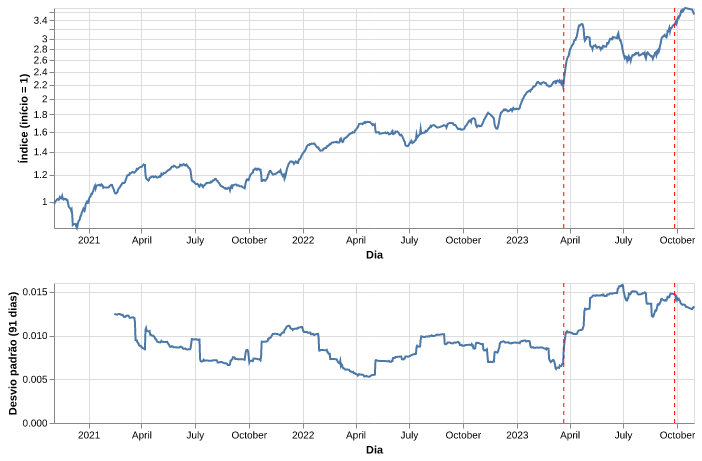

In [5]:
chart_params = load_params()["charts"]
market_daily = market_with_volatility(market)
event_frame = pl.DataFrame(chart_params["events"]).with_columns(pl.col("date").str.to_date())
event_rules = alt.Chart(event_frame).mark_rule(color="red", strokeDash=[4, 4]).encode(x="date:T")
volatility_title = f"Desvio padrão ({chart_params['volatility_days']} dias)"

# The log scale gives equal percent moves the same height.
index_line = (
    alt.Chart(market_daily)
    .mark_line()
    .encode(
        x=alt.X("date:T", title="Dia"),
        y=alt.Y("market_index:Q", title="Índice (início = 1)", scale=alt.Scale(type="log", zero=False, nice=False)),
    )
)

volatility_line = (
    alt.Chart(market_daily)
    .mark_line()
    .encode(x=alt.X("date:T", title="Dia"), y=alt.Y("volatility:Q", title=volatility_title))
)

market_figure = alt.vconcat(
    (index_line + event_rules).properties(width=640, height=220),
    (volatility_line + event_rules).properties(width=640, height=140),
)
market_figure

## Medir a dinâmica do mercado

Autocorrelação, correlação com o mercado e testes ADF e ARCH dizem se os retornos são previsíveis, se a
série do mercado é estacionária e se a volatilidade se agrupa. Esses resultados condicionam a escolha do
modelo.

In [6]:
def test_text_row(label: str, statistic: float, p_value: float) -> pl.DataFrame:
    """Write one test as a table row.

    Returns:
        One row with the label and the statistic with its p-value.

    """
    text = format_metric(statistic, ".2f") + f" (p = {format_metric(p_value, '.3f')})"

    return pl.DataFrame({"metric_name": [label], "metric_value": [text]})


dynamics = market_dynamics(prices, market)
dynamics_record = dynamics.row(0, named=True)

index_test = test_text_row(
    "Teste ADF: log do índice do mercado",
    dynamics_record["adf_index_statistic"],
    dynamics_record["adf_index_p_value"],
)

return_test = test_text_row(
    "Teste ADF: retorno do mercado",
    dynamics_record["adf_return_statistic"],
    dynamics_record["adf_return_p_value"],
)

arch_test_row = test_text_row(
    f"Teste ARCH-LM: retorno do mercado ({max(LAGS)} defasagens)",
    dynamics_record["arch_statistic"],
    dynamics_record["arch_p_value"],
)

dynamics_gt = (
    GT(
        pl.concat(
            [metric_text_table(dynamics, DYNAMICS_LABELS, DYNAMICS_FORMATS), index_test, return_test, arch_test_row]
        )
    )
    .tab_header(title="Dinâmica do Mercado — CS:GO")
    .cols_label(metric_name="Métrica", metric_value="Valor")
    .tab_source_note(
        "Mercado: média simples dos retornos diários limitados. "
        "Correlação: itens com 400 dias ou mais de retorno. ADF e ARCH-LM: estatística e p-valor. "
        "A autocorrelação negativa dentro dos itens pode refletir ruído no preço, não efeito de mercado."
    )
)
dynamics_gt

"Mercado: média simples dos retornos diários limitados. Correlação: itens com 400 dias ou mais de retorno. ADF e ARCH-LM: estatística e p-valor. A autocorrelação negativa dentro dos itens pode refletir ruído no preço, não efeito de mercado."


## Testar o ruído de preço

O preço de 24 horas é uma média de poucas vendas, então carrega ruído entre a oferta e a demanda. Esse
ruído cria autocovariância negativa e uma razão de variância abaixo de um: o preço volta de um dia para o
outro. A diferença implícita de Roll, duas vezes a raiz de menos a autocovariância, estima o tamanho do
ruído. A razão de variância do mercado fica acima de um: o ruído de cada item não se repete entre os
itens, então a média o cancela e deixa o componente comum, que persiste de um dia para o outro.

In [7]:
noise = price_noise(prices, market, eda_params["item_min_days"])

noise_gt = (
    GT(metric_text_table(noise, NOISE_LABELS, NOISE_FORMATS))
    .tab_header(title="Ruído de Preço — CS:GO")
    .cols_label(metric_name="Métrica", metric_value="Valor")
    .tab_source_note(
        "Itens com 400 dias ou mais de retorno. Autocovariância de primeira ordem do log do retorno. "
        "Razão de variância: variância da soma de 7 dias seguidos sobre 7 vezes a variância diária. "
        "Abaixo de 1 indica reversão típica de ruído de preço."
    )
)
noise_gt

Itens com 400 dias ou mais de retorno. Autocovariância de primeira ordem do log do retorno. Razão de variância: variância da soma de 7 dias seguidos sobre 7 vezes a variância diária. Abaixo de 1 indica reversão típica de ruído de preço.


## Testar a estacionariedade por item

O teste ADF por item verifica se o log do preço e o retorno têm raiz unitária. Espera-se que poucos itens
rejeitem a raiz unitária no preço e quase todos no retorno. A série de cada item usa os dias observados,
sem preencher lacunas.

In [8]:
stationarity = item_stationarity(prices, eda_params["item_min_days"])

stationarity_gt = (
    GT(metric_text_table(stationarity, STATIONARITY_LABELS, STATIONARITY_FORMATS))
    .tab_header(title="Estacionariedade por Item — CS:GO")
    .cols_label(metric_name="Métrica", metric_value="Valor")
    .tab_source_note(
        "Teste ADF por item a 5%, com até 7 defasagens. Itens com 400 dias ou mais de retorno. "
        "A série usa os dias observados, sem preencher lacunas."
    )
)
stationarity_gt

"Teste ADF por item a 5%, com até 7 defasagens. Itens com 400 dias ou mais de retorno. A série usa os dias observados, sem preencher lacunas."


## Exportar tabelas LaTeX e gráficos PNG

In [9]:
tables = {"dynamics": dynamics_gt, "price_noise": noise_gt, "stationarity": stationarity_gt}

write_outputs(tables, {"market": market_figure}, args.tables, args.images)

Written /mnt/external/projects/thesis/output/tables/dynamics.tex
Written /mnt/external/projects/thesis/output/tables/price_noise.tex
Written /mnt/external/projects/thesis/output/tables/stationarity.tex
Written /mnt/external/projects/thesis/output/images/market.png
